[aviso] vaderSentiment não instalado -> usando léxico simples de substituição.
Analisador: léxico simples | clientes Mensal+Fibra que cancelaram: 928
motivo
Oferta melhor da concorrência    29677.0
Preço alto / cobrança            24346.0
Outros / não classificado        16075.0
Forma de pagamento               15338.0
Quedas / instabilidade           12216.0
Velocidade lenta                  8905.0
Contrato / flexibilidade          4792.0
Suporte ruim                      4740.0
Mudança / não precisa mais        1006.0

Gráfico salvo em: c:\Users\gustagol\Documents\Projeto-Integrador-II\graficos_feedback\receita_por_motivo_mensal_fibra.png


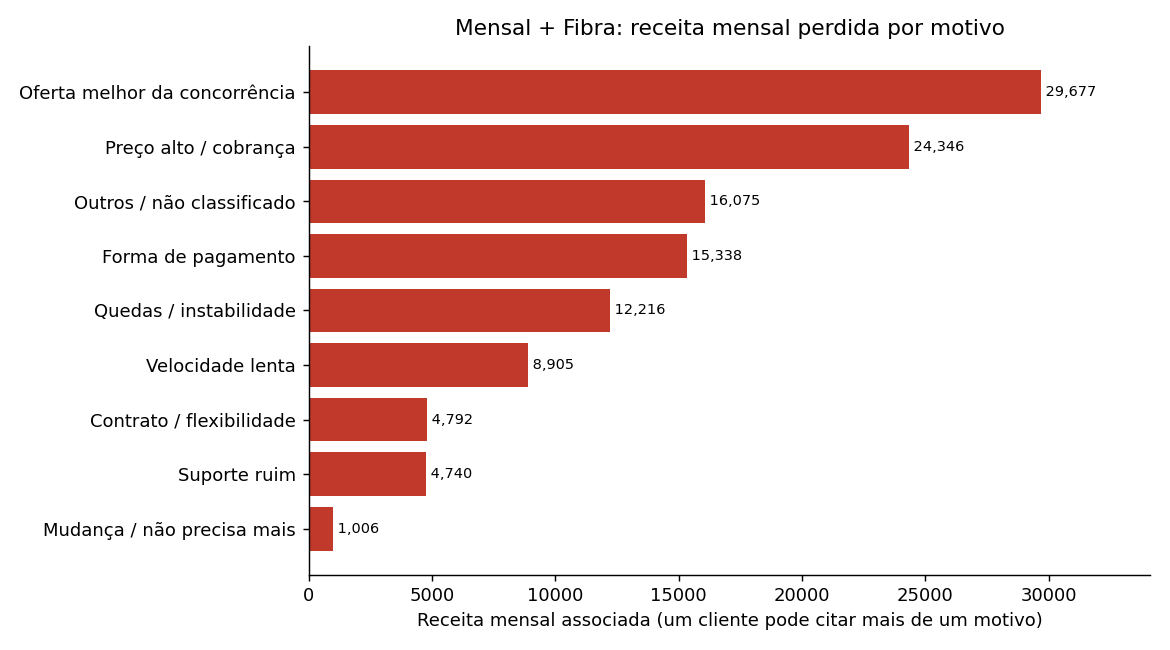

In [11]:
import argparse
import os
import re
 
import matplotlib.pyplot as plt
import pandas as pd
 
plt.rcParams.update({"figure.dpi": 130, "axes.spines.top": False, "axes.spines.right": False})
VERMELHO = "#c0392b"
 
TEMAS = {
    "Preço alto / cobrança": r"steep|expensive|pricey|overpriced|high(er)? (price|cost|charge|bill)|too much|cost(s|ly)?\b|price increase|rate increase|charges? (were|was|are|is)? ?(a bit |too |quite )?(high|steep|much)|not worth|value for",
    "Oferta melhor da concorrência": r"better deal|better offer|better value|cheaper|competitor|better price|lower (price|cost|rate)|savings?|promotion|another provider|different provider offering|more competitive",
    "Velocidade lenta": r"slow|speeds? (was|were|are|is)? ?(not|inconsistent)|lag|buffer|inconsistent speed|throttl|bandwidth",
    "Quedas / instabilidade": r"outage|interruption|disconnect|unreliable|intermittent|drop(s|ped)?\b|downtime|unstable|inconsistent (service|connect)|connectivity issue|no (internet|service) for",
    "Suporte ruim": r"customer (service|support)|tech(nical)? support|support (team|staff)|unhelpful|rude|long wait|on hold|representative|technician|lack of support|no support",
    "Forma de pagamento": r"(mail|mailing|mailed)(ing)? (in )?(a )?check|electronic check.{0,40}(inconvenient|outdated|hassle|cumbersome|annoying)|(inconvenient|outdated|hassle|cumbersome).{0,40}(check|payment)|payment (method|option)s?.{0,40}(inconvenient|outdated|limited|lacking|modern)|modern payment",
    "Contrato / flexibilidade": r"contract.{0,40}(inflexib|restrict|lock|commit|penalt|expir|renew)|flexib|commitment|early termination|locked in|long-term",
    "Falta de serviços extras": r"no (online )?(security|backup)|lack of (online )?(security|backup|protection)|additional services|streaming|tech support was not|no tech support",
    "Mudança / não precisa mais": r"moving|moved|relocat|no longer need|don't need|do not need|passed away|travel",
}
GATILHO_SAIDA = re.compile(r"decided to|decision to|switch|churn|cancel|however|but |unfortunately|ultimately|disappoint|dissatisf|frustrat", re.I)
NEG_FALLBACK = re.compile(r"steep|expensive|slow|outage|interrupt|unreliable|inconvenient|outdated|disappoint|dissatisf|frustrat|poor|bad|worse|unhappy|issue|problem|lack|unfortunately|difficult|hassle|not worth|too much", re.I)
 
 
def carregar_analisador():
    try:
        from vaderSentiment.vaderSentiment import SentimentIntensityAnalyzer
        sia = SentimentIntensityAnalyzer()
        return (lambda s: sia.polarity_scores(s)["compound"]), "VADER"
    except ImportError:
        print("[aviso] vaderSentiment não instalado -> usando léxico simples de substituição.")
        return (lambda s: -min(1.0, 0.35 * len(NEG_FALLBACK.findall(s))) if NEG_FALLBACK.search(s) else 0.05), "léxico simples"
 
 
def frases(texto):
    return [f.strip() for f in re.split(r"(?<=[.!?])\s+", str(texto)) if len(f.strip()) > 10]
 
 
def main():
    ap = argparse.ArgumentParser()
    ap.add_argument("--csv", default=os.path.join("dados", "silver", "history_silver.csv"))
    ap.add_argument("--out", default="graficos_feedback")
    a, _ = ap.parse_known_args()  # ignora argumentos extras do Jupyter (--f=...)
    os.makedirs(a.out, exist_ok=True)
 
    df = pd.read_csv(a.csv)
    seg = df[(df.Cancelamento == "Yes") & (df.Contrato == "Month-to-month") & (df.Servico_Internet == "Fiber optic")]
    score, nome = carregar_analisador()
    print(f"Analisador: {nome} | clientes Mensal+Fibra que cancelaram: {len(seg)}")
 
    registros = []
    for _, r in seg.iterrows():
        temas = set()
        for f in frases(r.Feedback_Cliente):
            if score(f) <= -0.05 or GATILHO_SAIDA.search(f):
                fl = f.lower()
                temas |= {t for t, rx in TEMAS.items() if re.search(rx, fl)}
        for t in temas or {"Outros / não classificado"}:
            registros.append((t, r.Cobranca_Mensal))
 
    rec = pd.DataFrame(registros, columns=["motivo", "cobranca"]).groupby("motivo").cobranca.sum().sort_values()
 
    fig, ax = plt.subplots(figsize=(9, 5))
    ax.barh(rec.index, rec.values, color=VERMELHO)
    for i, v in enumerate(rec.values):
        ax.text(v, i, f" {v:,.0f}", va="center", fontsize=8)
    ax.set_xlim(0, rec.max() * 1.15)
    ax.set_xlabel("Receita mensal associada (um cliente pode citar mais de um motivo)")
    ax.set_title("Mensal + Fibra: receita mensal perdida por motivo")
    fig.tight_layout()
    destino = os.path.join(a.out, "receita_por_motivo_mensal_fibra.png")
    fig.savefig(destino)
    plt.close(fig)
    print(rec.sort_values(ascending=False).round(0).to_string())
    print(f"\nGráfico salvo em: {os.path.abspath(destino)}")
    # Mostra o PNG salvo (funciona em Jupyter/VS Code sem depender do backend do matplotlib)
    try:
        from IPython import get_ipython
        from IPython.display import Image, display
        if get_ipython() is not None:
            display(Image(filename=destino))
            return
    except ImportError:
        pass
    plt.imshow(plt.imread(destino))
    plt.axis("off")
    plt.show()
 
 
if __name__ == "__main__":
    main()
 
